# 実験4 (ex004): EMNIST MCLR（強凸モデル）における FedSSO × MoQファミリー 10シード比較

論文 Table 1（上段右: EMNIST FOR MCLR, $d = 7,850, n_c = 62,800\,\mathrm{B}$）・Figure 4(b) の設定に準拠し、EMNIST Digits（10クラス, 280,000サンプル, $N=20$, $\mathrm{Dir}(\beta=0.1)$）上で全 11 手法を 10 シード（`42`〜`51`）で比較します。

In [1]:
import os
import torch
import pandas as pd
from model import verify_batched_mclr_equivalence
from utils import (
    DEFAULT_SEEDS, load_and_partition_emnist, run_multiseed_emnist_mclr,
    plot_emnist_mclr_curves, plot_emnist_mclr_boxplot, plot_filtered_results,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'})")
print(f"実験シード (10種類): {DEFAULT_SEEDS}")

使用デバイス: cuda (NVIDIA GeForce RTX 4080)
実験シード (10種類): [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]


In [2]:
clients, packed_clients, X_train, y_train, X_test, y_test, class_dist = load_and_partition_emnist(
    data_dir="../datasets", num_clients=20, beta=0.1, train_ratio=0.75, seed=42, device=device
)
max_diff = verify_batched_mclr_equivalence(clients, packed_clients, tau=5, batch_size=100, lr=0.003, device=device)
print(f"EMNIST train={X_train.shape}, test={X_test.shape} | 並列SGD最大誤差: {max_diff:.3e}")

EMNIST train=torch.Size([209991, 784]), test=torch.Size([70009, 784]) | 並列SGD最大誤差: 7.451e-09


In [3]:
algo_configs = [
    {"name": "FedAvg",        "algo": "FedAvg",        "lr": 0.03},
    {"name": "FedSSO",        "algo": "FedSSO",        "lr": 0.003, "eta": 1.0},
    {"name": "FedSSO-NAQ",    "algo": "FedSSO-NAQ",    "lr": 0.003, "eta": 1.0, "mu": 0.30},
    {"name": "FedSSO-MoQ",    "algo": "FedSSO-MoQ",    "lr": 0.003, "eta": 1.0, "mu": 0.30},
    {"name": "FedSSO-AdaNAQ", "algo": "FedSSO-AdaNAQ", "lr": 0.003, "eta": 1.0, "max_mu": 0.40},
    {"name": "FedSSO-AdaMoQ", "algo": "FedSSO-AdaMoQ", "lr": 0.003, "eta": 1.0, "max_mu": 0.40},
    {"name": "FedSSO-LBFGS",  "algo": "FedSSO-LBFGS",  "lr": 0.003, "eta": 1.0, "m_size": 10},
    {"name": "FedSSO-LNAQ",   "algo": "FedSSO-LNAQ",   "lr": 0.003, "eta": 1.0, "max_mu": 0.40, "m_size": 10},
    {"name": "FedSSO-LMoQ",   "algo": "FedSSO-LMoQ",   "lr": 0.003, "eta": 1.0, "max_mu": 0.40, "m_size": 10},
    {"name": "FedSSO-MLNAQ",  "algo": "FedSSO-MLNAQ",  "lr": 0.003, "eta": 1.0, "max_mu": 0.40},
    {"name": "FedSSO-MLMoQ",  "algo": "FedSSO-MLMoQ",  "lr": 0.003, "eta": 1.0, "max_mu": 0.40},
]
summary_df, per_seed_df, curves_dict = run_multiseed_emnist_mclr(
    algo_configs=algo_configs, packed_clients=packed_clients,
    X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
    seeds=DEFAULT_SEEDS, rounds=200, tau=5, batch_size=100,
    save_log_dir="../datasets/ex004_emnist_mclr_logs",
    history_csv_path="../datasets/ex004_emnist_mclr_history.csv",
)
summary_df.to_csv("../datasets/ex004_emnist_mclr_summary.csv", index=False)
per_seed_df.to_csv("../datasets/ex004_emnist_mclr_per_seed.csv", index=False)
summary_df

,Algorithm,Comm_Per_Iter,Loss_Ave,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,MaxAcc_Ave,Clip_Ave,Reset_Ave,Server_Time_ms,Server_Mem_MB,Bytes@0.83,Reach@0.40,Iter@0.40,Comm@0.40,Reach@0.60,Iter@0.60,Comm@0.60,Reach@0.80,Iter@0.80,Comm@0.80,Reach@0.83,Iter@0.83,Comm@0.83,Reach@0.84,Iter@0.84,Comm@0.84
0,FedAvg,1.000,0.258384,0.928616,0.928681,0.928952,0.928066,0.000241,0.928722,0.0,0.0,0.007476,0.029945,376800,10/10,1.0,1.0,10/10,2.0,2.0,10/10,4.3,4.3,10/10,6.0,6.0,10/10,7.0,7.0
1,FedSSO,1.000,0.228336,0.935748,0.936301,0.939951,0.924810,0.004060,0.940342,0.0,1.0,2.057513,235.190964,383080,10/10,1.0,1.0,10/10,1.7,1.7,10/10,5.8,5.8,10/10,6.1,6.1,10/10,6.6,6.6
2,FedSSO-NAQ,1.995,0.232942,0.933956,0.934473,0.937494,0.927609,0.002745,0.939591,0.0,1.1,2.018903,235.250854,703360,10/10,1.0,1.0,10/10,1.7,2.4,10/10,5.7,10.4,10/10,6.1,11.2,10/10,6.3,11.6
3,FedSSO-MoQ,1.000,0.250288,0.928094,0.933687,0.938822,0.897699,0.012782,0.940169,0.0,1.0,2.053578,235.280800,514960,10/10,1.0,1.0,10/10,1.7,1.7,10/10,7.9,7.9,10/10,8.2,8.2,10/10,8.7,8.7
4,FedSSO-AdaNAQ,1.995,0.239259,0.932846,0.934116,0.938622,0.925795,0.004232,0.939045,0.0,1.6,2.059412,235.250854,715920,10/10,1.0,1.0,10/10,1.7,2.4,10/10,5.6,10.2,10/10,6.2,11.4,10/10,6.5,12.0
5,FedSSO-AdaMoQ,1.000,0.256208,0.925831,0.929609,0.937122,0.909826,0.009664,0.940028,0.0,1.0,2.009024,235.280800,577760,10/10,1.0,1.0,10/10,1.7,1.7,10/10,8.9,8.9,10/10,9.2,9.2,10/10,9.3,9.3
6,FedSSO-LBFGS,1.000,0.232295,0.935338,0.935380,0.938237,0.930723,0.001905,0.939061,0.2,1.0,1.200400,0.718689,251200,10/10,1.0,1.0,10/10,1.7,1.7,10/10,3.5,3.5,10/10,4.0,4.0,10/10,4.3,4.3
7,FedSSO-LNAQ,1.995,0.235318,0.934668,0.934758,0.936851,0.931994,0.001704,0.938208,0.0,1.1,1.772871,0.778580,552640,10/10,1.0,1.0,10/10,1.7,2.4,10/10,4.5,8.0,10/10,4.9,8.8,10/10,5.5,10.0
8,FedSSO-LMoQ,1.000,0.306549,0.908889,0.926338,0.934451,0.811710,0.038674,0.937555,0.4,1.0,1.484257,0.808525,251200,10/10,1.0,1.0,10/10,1.7,1.7,10/10,3.5,3.5,10/10,4.0,4.0,10/10,4.4,4.4
9,FedSSO-MLNAQ,1.995,0.262749,0.930529,0.930652,0.932509,0.928481,0.001309,0.932919,87.1,1.0,0.620368,0.239563,489840,10/10,1.0,1.0,10/10,1.7,2.4,10/10,4.1,7.2,10/10,4.4,7.8,10/10,5.0,9.0


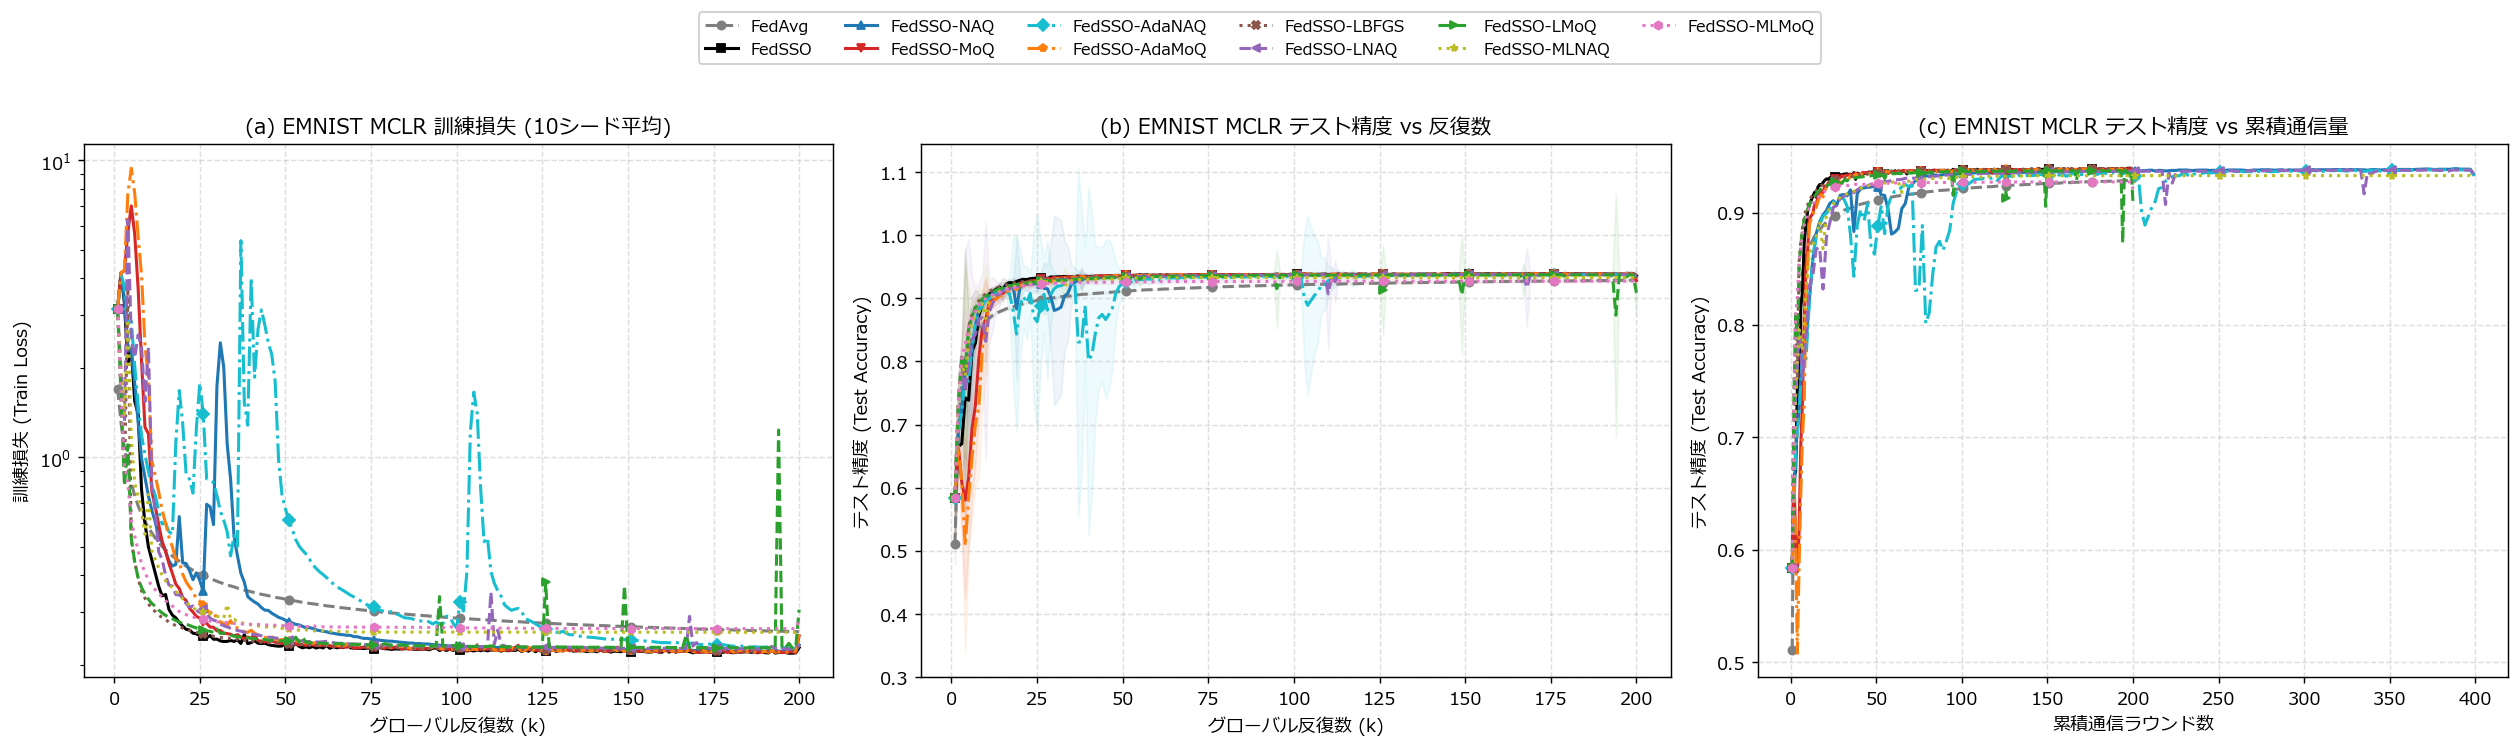

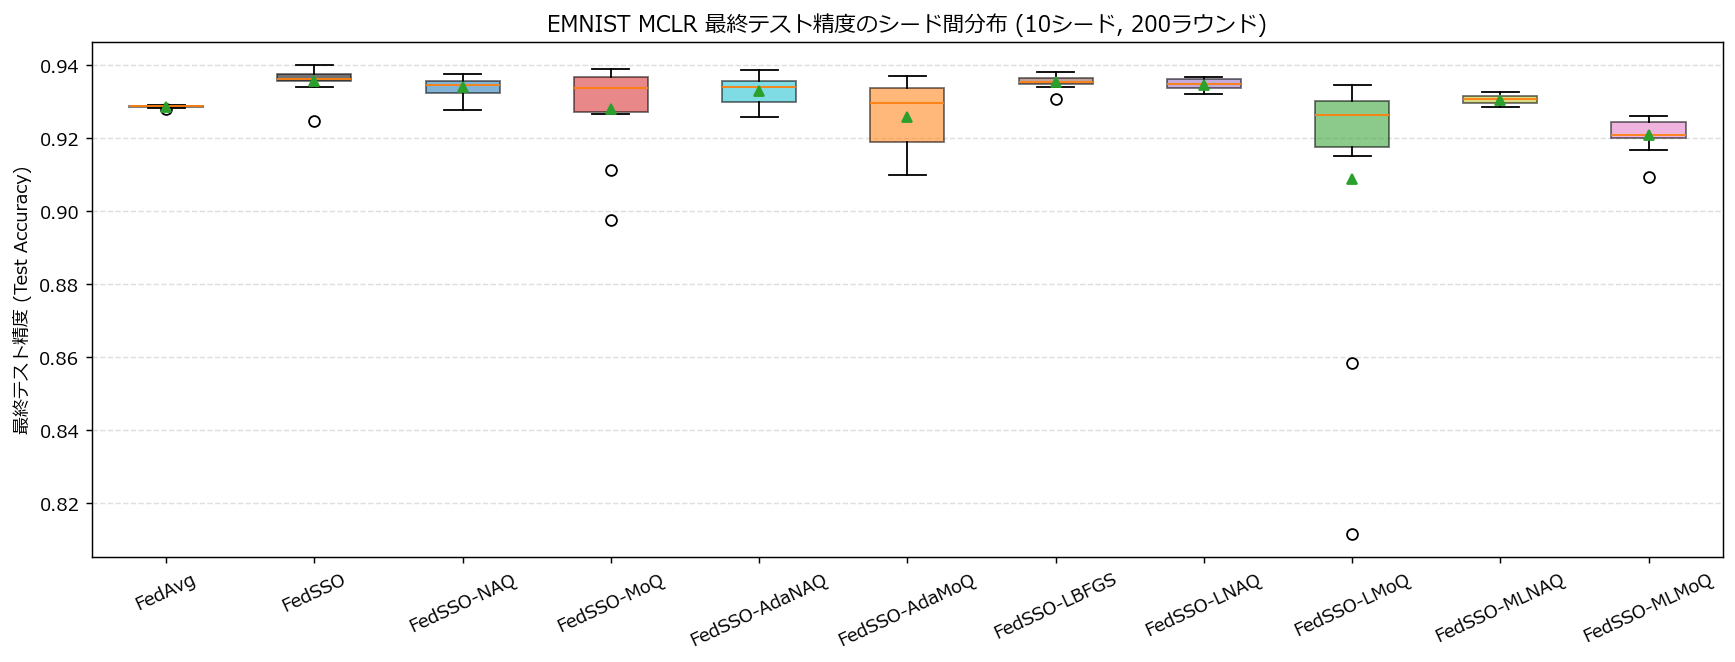

In [4]:
os.makedirs("../report/img", exist_ok=True)
plot_emnist_mclr_curves(curves_dict, save_path="../report/img/ex004_emnist_mclr_curves.png")
plot_emnist_mclr_boxplot(per_seed_df, save_path="../report/img/ex004_emnist_mclr_boxplot.png")

## 特定のシード値・アルゴリズムに絞ったグラフ表示

保存済みの全履歴 CSV（`../datasets/ex004_emnist_mclr_history.csv`）から任意のアルゴリズム・シード値だけを指定して再描画できます。 `SELECTED_SEEDS = None` のときは全シード平均のみを自動表示・出力します。

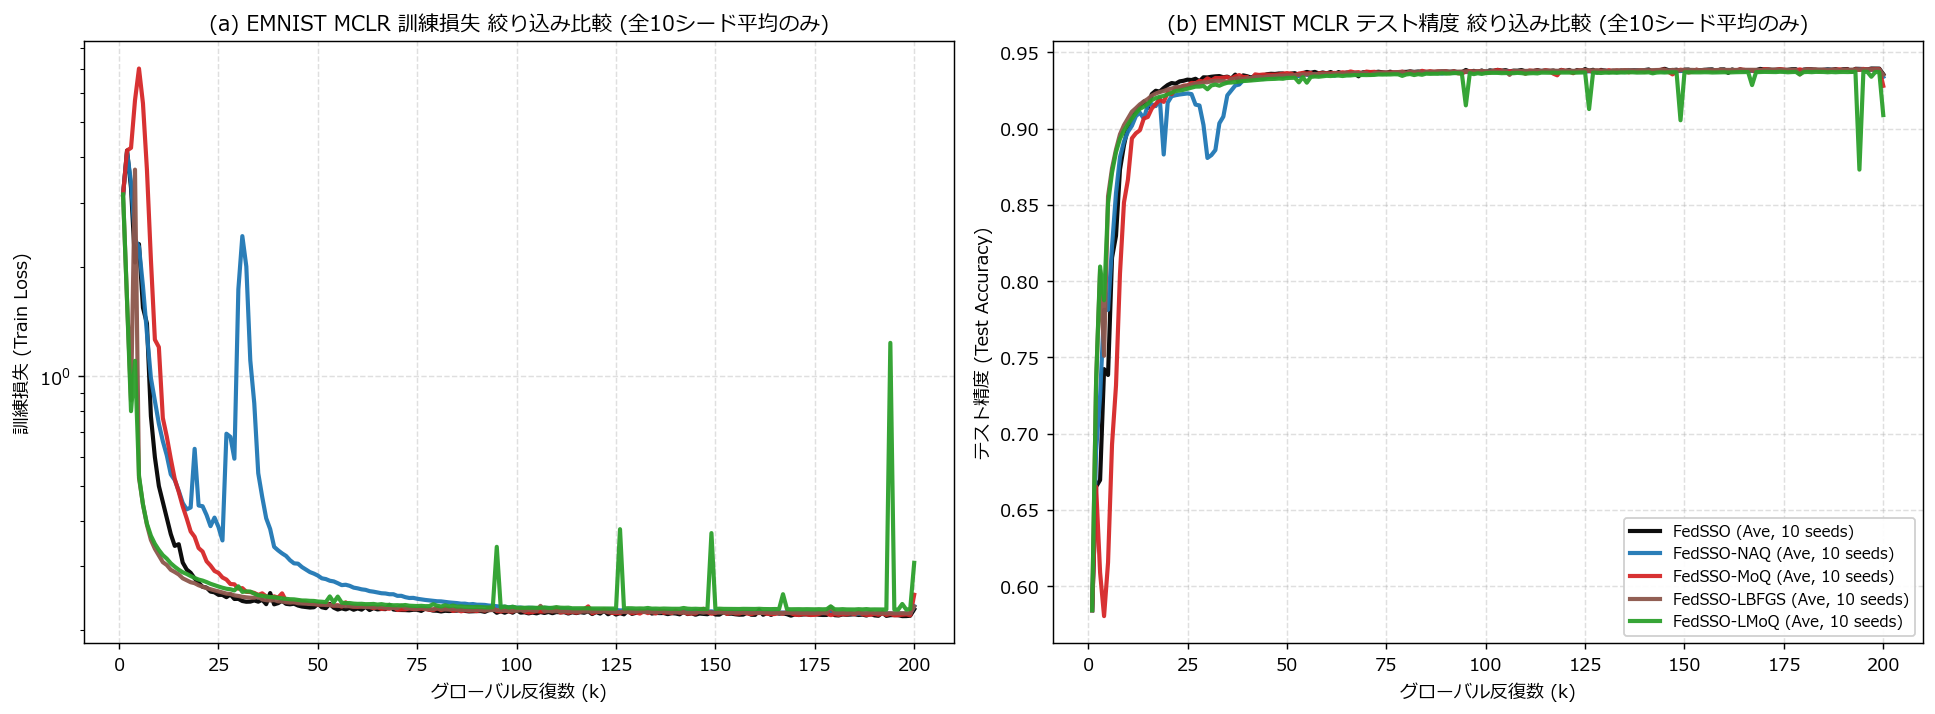

,Algorithm,Seeds,Round,Comm_Round,Train_Loss_Ave,Test_Acc_Ave
0,FedSSO,10,200,200.0,0.228336,0.935748
1,FedSSO-NAQ,10,200,399.0,0.232942,0.933956
2,FedSSO-MoQ,10,200,200.0,0.250288,0.928094
3,FedSSO-LBFGS,10,200,200.0,0.232295,0.935338
4,FedSSO-LMoQ,10,200,200.0,0.306549,0.908889


In [5]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示
# 利用可能なアルゴリズム:
#   ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-AdaMoQ",
#    "FedSSO-LBFGS", "FedSSO-LNAQ", "FedSSO-LMoQ", "FedSSO-MLNAQ", "FedSSO-MLMoQ"]
#   None を指定すると全手法が対象になります
# 利用可能なシード値: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] (None で全シード対象)
SELECTED_ALGOS = ["FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-LBFGS", "FedSSO-LMoQ"]
SELECTED_SEEDS = None       # None で全10シード対象（例: [42, 46] で特定シードに絞り込み）
X_AXIS_MODE = "round"       # "round" (反復数) または "comm" (累積通信ラウンド数)
SHOW_MEAN_CURVE = True      # 複数シード指定時に平均太線を重ね描きするか
PLOT_MEAN_ONLY = "auto"     # "auto": SELECTED_SEEDS=None 時に平均線のみ描画 / True: 平均のみ / False: 個別シードも描画
TABLE_MEAN_ONLY = "auto"    # "auto": SELECTED_SEEDS=None 時に平均のみの行を出力 / True: 平均のみ / False: シード別に出力

filtered_df = plot_filtered_results(
    selected_algos=SELECTED_ALGOS,
    selected_seeds=SELECTED_SEEDS,
    history_csv_path="../datasets/ex004_emnist_mclr_history.csv",
    log_dir="../datasets/ex004_emnist_mclr_logs",
    x_axis=X_AXIS_MODE,
    show_mean=SHOW_MEAN_CURVE,
    plot_mean_only=PLOT_MEAN_ONLY,
    table_mean_only=TABLE_MEAN_ONLY,
)
filtered_df